In [ ]:
"""
This notebook is to teach AI to HRSM on December 6
"""

# https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data/data
import pandas as pd

# Load dataset
df = pd.read_csv('AB_NYC_2019.csv')

In [ ]:
# Check for NAs
df.isna().any()

In [ ]:
# Remove Columns
df.drop(['name','host_name'],axis=1,inplace=True)

In [ ]:
# Check for duplicates
df.duplicated().any()

False

<Axes: xlabel='price', ylabel='Count'>

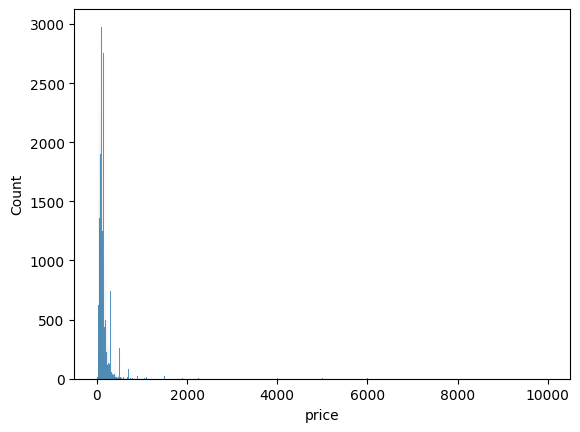

In [89]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df['price'])

<Axes: xlabel='price', ylabel='Count'>

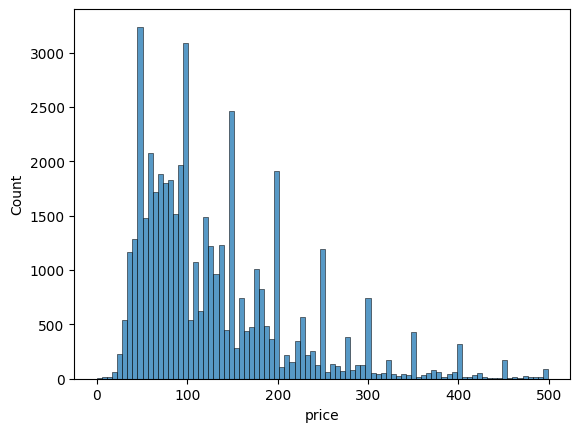

In [90]:
sns.histplot(df.loc[df['price'] < 500,'price'])

<Axes: xlabel='price', ylabel='Count'>

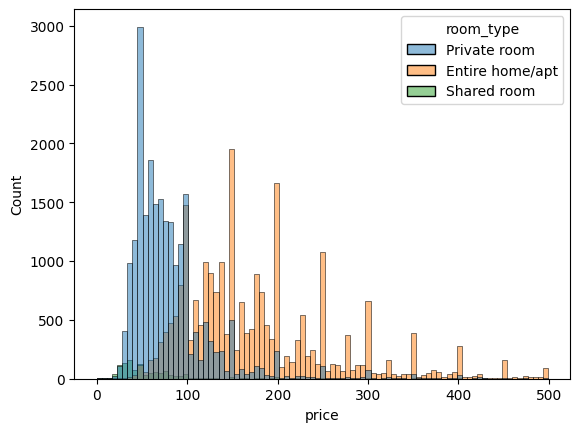

In [91]:
sns.histplot(df.loc[df['price'] < 500],x='price',hue='room_type')

<Axes: xlabel='price', ylabel='room_type'>

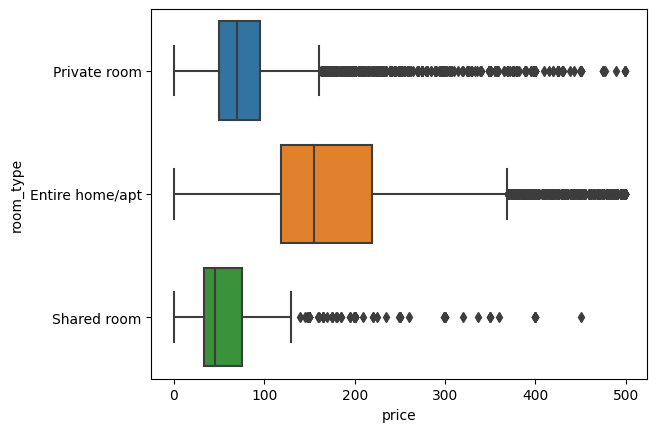

In [92]:
sns.boxplot(df.loc[df['price'] < 500],x='price',y='room_type')

In [93]:
# Top 10 hosts by number of listings
top_hosts = df['host_id'].value_counts().head(10)
print(top_hosts)

# Average price for hosts with many vs. few listings
high_listings = df[df['calculated_host_listings_count'] > 10]
low_listings = df[df['calculated_host_listings_count'] <= 10]
print("Average price for high-listing hosts:", high_listings['price'].mean())
print("Average price for low-listing hosts:", low_listings['price'].mean())

219517861    327
107434423    232
30283594     121
137358866    103
16098958      96
12243051      96
61391963      91
22541573      87
200380610     65
7503643       52
Name: host_id, dtype: int64
Average price for high-listing hosts: 216.11526794742164
Average price for low-listing hosts: 148.62532659815363


neighbourhood_group
Bronx            26.004583
Brooklyn         24.202845
Manhattan        20.985596
Queens           27.700318
Staten Island    30.941019
Name: number_of_reviews, dtype: float64


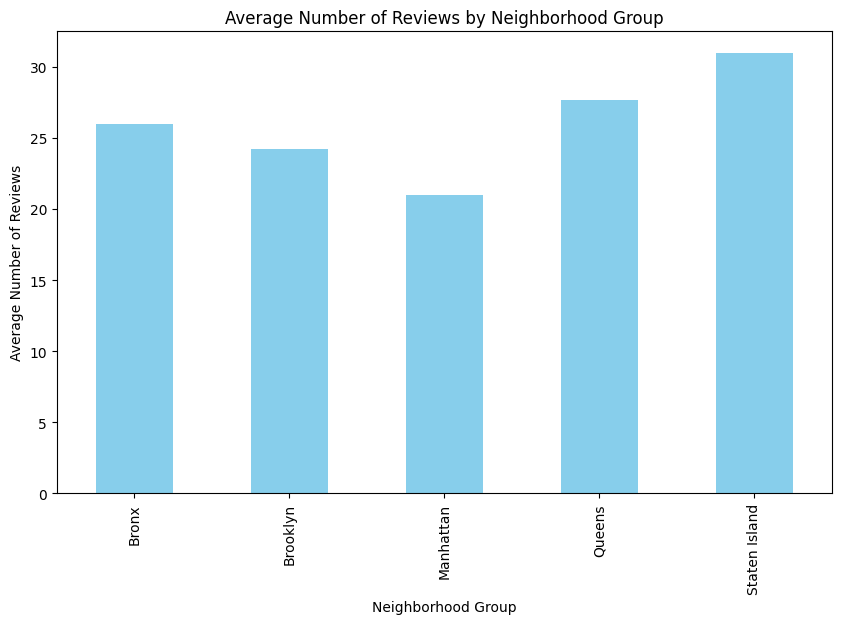

In [94]:
# Average number of reviews by neighborhood group
avg_reviews = df.groupby('neighbourhood_group')['number_of_reviews'].mean()
print(avg_reviews)

# Visualization
plt.figure(figsize=(10, 6))
avg_reviews.plot(kind='bar', color='skyblue')
plt.title('Average Number of Reviews by Neighborhood Group')
plt.xlabel('Neighborhood Group')
plt.ylabel('Average Number of Reviews')
plt.show()

/var/folders/_z/379dczw91pg5245qx8z89jw80000gn/T/ipykernel_97921/2979319435.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr = df.corr(method='kendall')


Index(['id', 'host_id', 'neighbourhood_group', 'neighbourhood', 'latitude',
       'longitude', 'room_type', 'price', 'minimum_nights',
       'number_of_reviews', 'last_review', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365', 'cluster'],
      dtype='object')

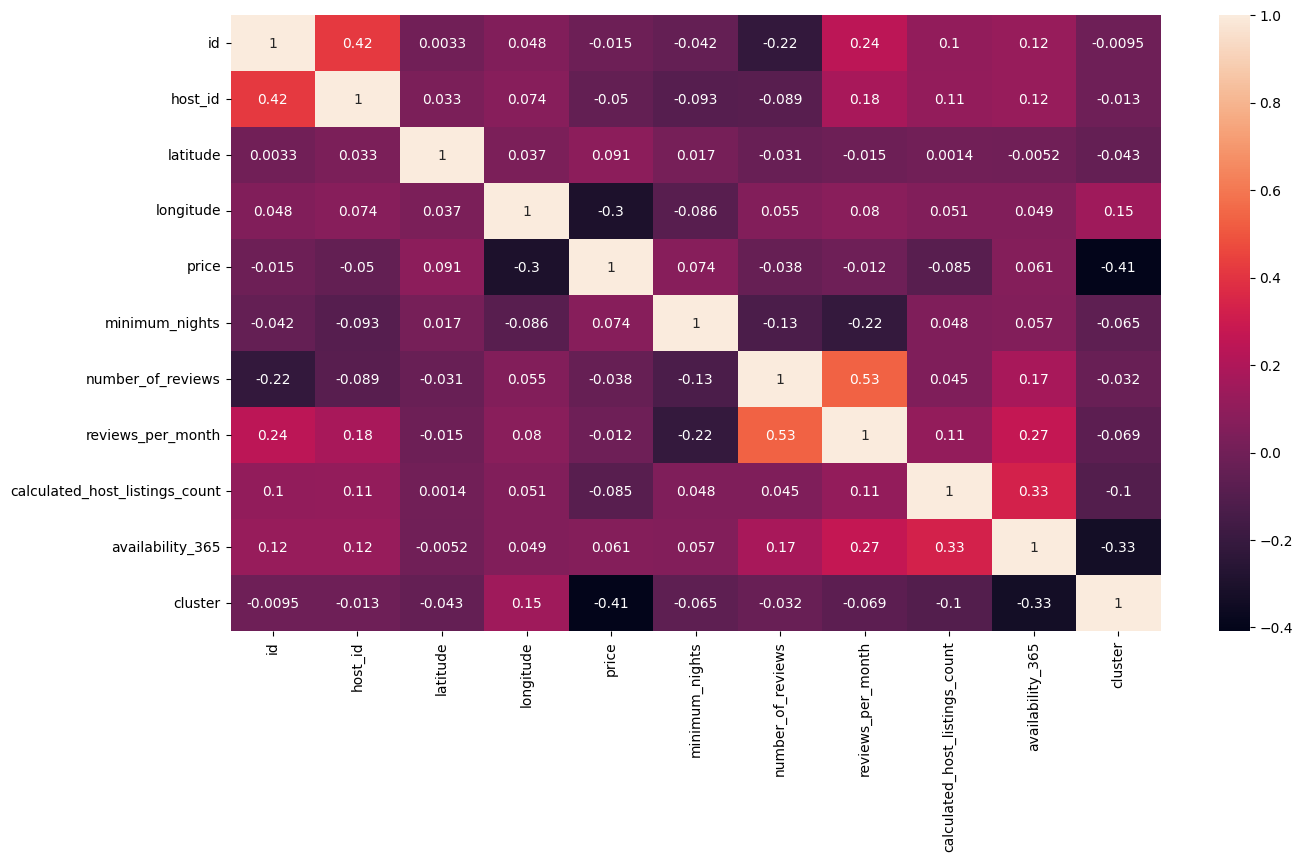

In [108]:
corr = df.corr(method='kendall')
plt.figure(figsize=(15,8))
sns.heatmap(corr, annot=True)
df.columns

/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


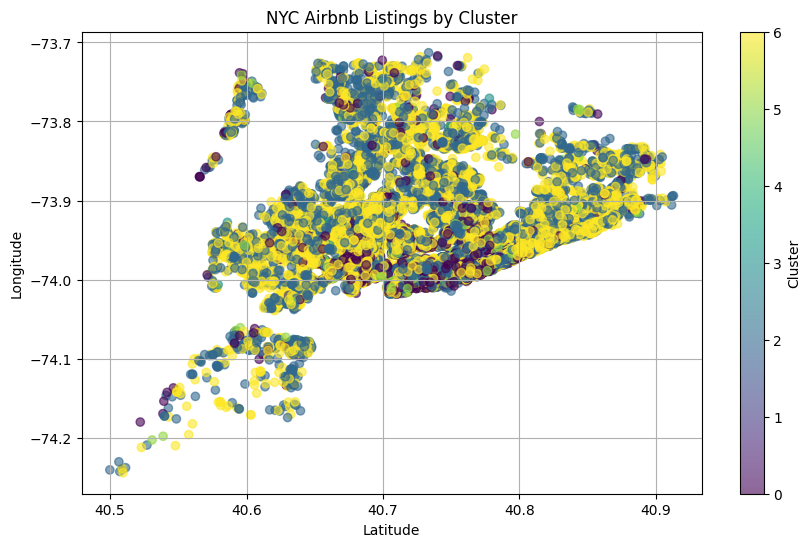

In [96]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Select relevant features for clustering
features = df[['price', 'latitude', 'longitude', 'availability_365']]

# Apply k-means clustering with 3 clusters
kmeans = KMeans(n_clusters=7, random_state=42)
df['cluster'] = kmeans.fit_predict(features)

# Scatter plot for latitude and longitude, colored by cluster
plt.figure(figsize=(10, 6))
plt.scatter(df['latitude'], df['longitude'], c=df['cluster'], cmap='viridis', alpha=0.6)
plt.colorbar(label='Cluster')
plt.title('NYC Airbnb Listings by Cluster')
plt.xlabel('Latitude')
plt.ylabel('Longitude')
plt.grid(True)
plt.show()

/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


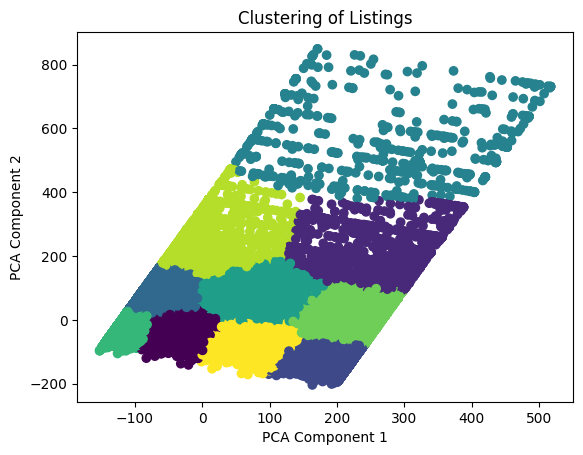

In [97]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Select features and scale them
features = df[['price', 'latitude', 'longitude', 'availability_365']]
features = features[features['price'] < 1000]  # Remove outliers

# K-means clustering
kmeans = KMeans(n_clusters=10, random_state=42)
features['cluster'] = kmeans.fit_predict(features)

# PCA for visualization
pca = PCA(n_components=2)
pca_result = pca.fit_transform(features[['price', 'latitude', 'longitude', 'availability_365']])

# Plot clusters
plt.scatter(pca_result[:, 0], pca_result[:, 1], c=features['cluster'], cmap='viridis')
plt.title('Clustering of Listings')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()